In [44]:
# Script to simulate DF using fundamental signal components 
# 2026-09-24
# Morena 


using LinearAlgebra
using Plots
using SignalAnalysis
using FFTW
using Statistics

const MIC_NUMBER = 3
const BASELINE = 0.017 # to avoid spatial aliasing, calculated with fmax=10088kHz, b<=[(c/fmax)/2 = lambda_min/2] 
const C = 343
SRCDOA_POINTS = 3



# Signal simulation
fs = 44100
f = 4000 # F should be 10088 max for broadband 
duration = 3
t = 0:1/fs:duration-1/fs


#theta_pre = rand()*2*(pi)
theta_pre = 22.5*(pi/180)


# Mic position set
mic = [zeros(MIC_NUMBER) for _ in 1:2]
mic[1][1] =  BASELINE/2
mic[1][3] = -BASELINE/2
mic[2][1] = -BASELINE*sqrt(3)/6
mic[2][2] =  BASELINE*sqrt(3)/3
mic[2][3] = -BASELINE*sqrt(3)/6

p1 = [mic[1][1], mic[2][1]]
p2 = [mic[1][2], mic[2][2]]
p3 = [mic[1][3], mic[2][3]]


tau1_21 = (BASELINE*sin((30*(pi/180)-theta_pre)))/C
tau1_31 = (BASELINE*cos(theta_pre))/C

f2 = 6000
f3 = 9500
source1 = sin.(2*pi*f .* t) .+ sin.(2*pi*f2 .* t) .+ sin.(2*pi*f3 .* t)


# Signals received by each microphone

sigMic1 = source1 .+ 0.01 .* (randn(size(source1)) .+ 1im .* randn(size(source1)))
sigMic2 = sin.(2*pi*f .* (t.-tau1_21)) .+ 0.01 .* (randn(size(source1)) .+ 1im .* randn(size(source1)))
sigMic3 = sin.(2*pi*f .* (t.-tau1_31)) .+ 0.01 .* (randn(size(source1)) .+ 1im .* randn(size(source1)))


@show theta_pre*(180/pi)

theta_pre * (180 / pi) = 22.5


22.5

SOURCE_NUMBER_all = [1, 1]
num_sources = 1
DOA = [22.5]


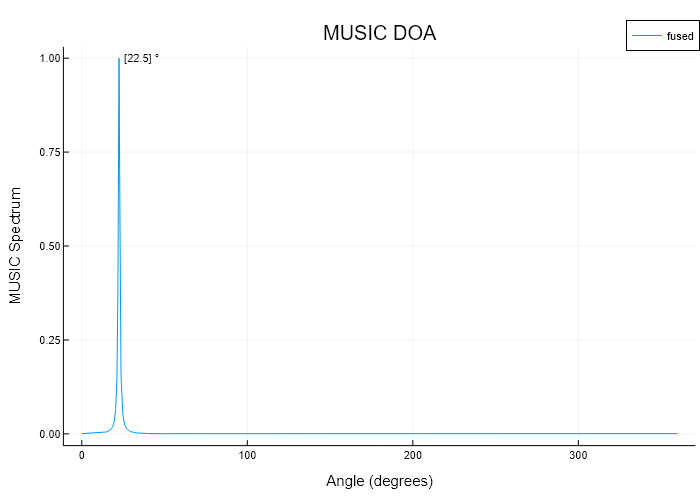

In [45]:
# Signal processing assuming the signals are not known

# BROADBAND SIGNIFICANT PARAMETERs
Ns = length(sigMic1)
Fmin = 2000
Frame_len = 1024
overlap = 0.5
window = 0.5.* (1 .- cos.(2*pi.*(0:Frame_len-1) ./ Frame_len))
Hop = div(Frame_len,2)
Nf = 1+div(Ns-Frame_len, Hop)
Nb = Frame_len
freqs = (0:Nb-1).*(fs/Frame_len)


# frame creation
X1 = zeros(ComplexF64, Nb,Nf)
X2 = zeros(ComplexF64, Nb,Nf)
X3 = zeros(ComplexF64, Nb,Nf)


for i in 1:Nf
    idx = (i-1)*Hop .+ (1:Frame_len)
    X1[:,i] = fft(sigMic1[idx] .*window)
    X2[:,i] = fft(sigMic2[idx].*window)
    X3[:,i] = fft(sigMic3[idx].*window)
end

# Determine the nenergy of the frequency bins in the frames and kill DC
energy = zeros(div(Frame_len, 2) + 1)
for b in 1:div(Frame_len, 2) + 1
    energy[b] = sum(abs2.(X1[b, :])) + sum(abs2.(X2[b, :])) + sum(abs2.(X3[b, :]))
end
energy[1] = 0

# Determine frequency bins inside the range 0f 2kHz to 10.088kHz
inband = findall(j -> (Fmin <= freqs[j]) && (freqs[j] <= f), 1:Nb)
thrshld = 0.1*median(energy[inband]) # set threshold to filter frequency bins with low energy
significant_idxs = [j for j in inband if energy[j] > thrshld]
significant_freqs = freqs[significant_idxs]


# MUSIC algorithm 
angles = 0:0.1:359.9
spectrum = zeros(length(angles))
spectrum_fused = zeros(length(angles))
SOURCE_NUMBER_all = Int[]

for b in significant_idxs
    sigf = freqs[b]

    sigs = permutedims(hcat(X1[b, :], X2[b, :], X3[b, :]))
    covMatrix = (sigs * sigs') / size(sigs, 2)
    E = eigen(Hermitian(covMatrix))
    eigenvalues = max.(E.values, eps(Float64))
    N = size(sigs, 2)
#=
    mdl = zeros(MIC_NUMBER)
    for i in 0:MIC_NUMBER-1
        noise_eigs = eigenvalues[1:MIC_NUMBER-i]
        geometric_mean = exp(mean(log.(noise_eigs)))
        arithmetic_mean = mean(noise_eigs)
        mdl[i+1] = -(MIC_NUMBER-i)*N*log(geometric_mean/arithmetic_mean)+0.5*i*(2*MIC_NUMBER-i)*log(N)
    end
    
    SOURCE_NUMBER = argmin(mdl) - 1
=#
    SOURCE_NUMBER = count(>(0.01 * maximum(eigenvalues)), eigenvalues)
 
    if (SOURCE_NUMBER >= MIC_NUMBER)
        continue
    end
    push!(SOURCE_NUMBER_all, SOURCE_NUMBER)

    En = E.vectors[:, 1:MIC_NUMBER-SOURCE_NUMBER]

    #MUSIC Scan
    for i in 1:length(angles)
        angle = deg2rad(angles[i])
        tau21 = (BASELINE*sin((30*(pi/180)-angle)))/C
        tau31 = (BASELINE*cos(angle))/C
        steering_vector = [1; exp(-1*im * 2*pi * sigf * tau21); exp(-1*im * 2 *pi * sigf * tau31)]
        spectrum[i] = 1 / real(steering_vector' * En * En' * steering_vector)
    end

    spectrum_fused .+= energy[b] .* (spectrum ./ maximum(spectrum))
end
spectrum_fused ./= maximum(spectrum_fused)

pk = Int[]
n = length(spectrum_fused)
for i in 1:n
    if (i == 1)
        left_index  = 1;
        right_index = 1;
    
    elseif (i == n)
        left_index  = i-1;
        right_index = i;
        
    else
        left_index  = i-1;
        right_index = i+ 1;
    end
        
    current_value = spectrum_fused[i]
    left_value    = spectrum_fused[left_index]
    right_value   = spectrum_fused[right_index]

    if current_value > left_value && current_value >= right_value
        push!(pk, i)
    end
end

num_sources = length(SOURCE_NUMBER_all) > 0 ? maximum(SOURCE_NUMBER_all) : 0
@show SOURCE_NUMBER_all
@show num_sources


    pk = sort(pk, by = i -> -spectrum_fused[i])[1:min(num_sources, length(pk))]
    DOA = angles[pk]
    @show DOA

    p = plot(angles, spectrum_fused, xlabel="Angle (degrees)", ylabel="MUSIC Spectrum", title="MUSIC DOA", label="fused")
    
    annotate!(DOA, maximum(spectrum_fused), text(" $DOA °", :left, 8))
    

display(p)

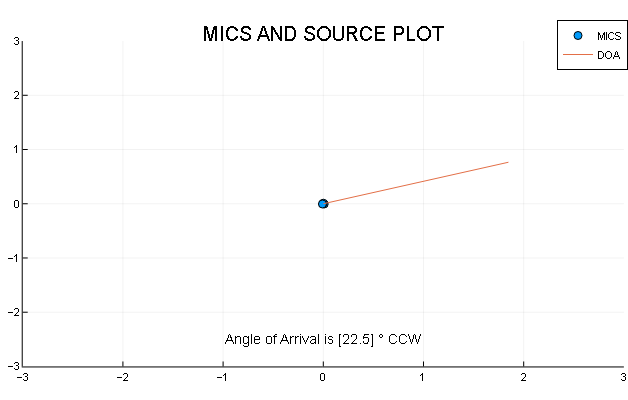

In [46]:
plotly()

srcDOA = [zeros(SRCDOA_POINTS) for _ in 1:2]
for i in 1:SRCDOA_POINTS
    r = i-1
    srcDOA[1][i] = r*cos.(DOA[1]*(pi/180))
    srcDOA[2][i] = r*sin.(DOA[1]*(pi/180))
end

scatter(mic[1], mic[2], xlims=(-3, 3), ylims=(-3, 3), title="MICS AND SOURCE PLOT", label = "MICS")
plot!(srcDOA[1], srcDOA[2], label = "DOA")
aoa = text("Angle of Arrival is $DOA ° CCW", :black, :right, 10)
annotate!(1, -2.5, aoa)